# Lesson 12: CSV to `geoDataFrame` + Streamline your code

Before class, make sure you can import the data we will use in [lesson 12](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html). Run the three code cells in this notebook. If they all run without errors, you are ready for class!

By the end of lesson 12, you will be able to:

- create a `geopandas.GeoDataFrame` from a CSV with longitude and latitude columns
- format printed output using f-strings
- use `for` loops, alone and with `zip()`, to avoid repeating code
- check that your code does what you expect using `assert`
- create figures with multiple axes
- write functions with docstrings to reuse code

## About the data

We will use two datasets:

1. **Power plants**: a CSV with the operable electric generating plants in the United States by energy source, as of February 2025, from the U.S. Energy Information Administration (EIA). We will read it directly from its URL, so you don't need to download it. See the [dataset's page and metadata](https://hub.arcgis.com/datasets/fedmaps::power-plants-in-the-u-s--2/about).

2. **US states**: the 2026 TIGER shapefile of the US states from the United States Census Bureau. See the [TIGER/Line shapefiles page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) and the [technical documentation](https://www2.census.gov/geo/pdfs/maps-data/data/tiger/tgrshp2026/TGRSHP2026_TechDoc.pdf) for the metadata. To download it:
    1. At the [2026 TIGER page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html), under Download, click on "Web Interface".
    2. For year, select 2026, and for layer type select "States (and equivalent)". Click submit.
    3. Click on "Download national file".
    4. Unzip the file and move the `tl_2026_us_state` folder into a `data/` folder at the same level as this notebook.

Read the information about both datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html) before class.

## Import libraries

In [1]:
import os

import pandas as pd
from pandas.api.types import is_string_dtype, is_numeric_dtype
import geopandas as gpd
import matplotlib.pyplot as plt


# Display all columns when looking at dataframes
pd.set_option("display.max_columns", None)

## Import power plants data

In [2]:
URL = 'https://raw.githubusercontent.com/carmengg/eds-220-book/refs/heads/main/data/power_plants_epsg4269.csv'
power_plants = pd.read_csv(URL)

power_plants.head(3)

,objectid,plant_code,plant_name,utility_id,utility_name,sector_name,street_address,city,county,state,zip,primsource,source_desc,tech_desc,install_mw,total_mw,bat_mw,bio_mw,coal_mw,geo_mw,hydro_mw,hydrops_mw,ng_mw,nuclear_mw,crude_mw,solar_mw,wind_mw,other_mw,source,period,longitude,latitude
0,62897,1873,Tower,20910,Wolverine Power Supply Coop,Electric Utility,9663 Cooperative Road,Tower,Cheboygan,Michigan,49792,petroleum,Petroleum = 19.3 MW,Petroleum Liquids,21.3,19.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-84.294970,45.362818
1,62898,1874,Caro,18895,Thumb Electric Coop of Mich,Electric Utility,2437 East Dayton Road,Caro,Tuscola,Michigan,48723,petroleum,Petroleum = 8.5 MW,Petroleum Liquids,9.4,8.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.5,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-83.327806,43.465899
2,62899,1875,Ubly,18895,Thumb Electric Coop of Mich,Electric Utility,4159 Ubly Road,Ubly,Huron,Michigan,48475,petroleum,Petroleum = 12.3 MW,Petroleum Liquids,12.4,12.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-82.938806,43.721699


## Create geodataframe from CSV

Known from metadata: CRS of the power plants has the code EPSG:4269

In [3]:
# Create points from latitude and longitude
points = gpd.points_from_xy( power_plants['longitude'],
                  power_plants['latitude'])

# Create geodataframe
power_plants = gpd.GeoDataFrame(power_plants, # Data
                               geometry=points,
                               crs='EPSG:4269')

In [4]:
power_plants.geometry

0         POINT (-84.29497 45.36282)
1         POINT (-83.32781 43.46590)
2         POINT (-82.93881 43.72170)
3         POINT (-85.42600 43.83930)
4         POINT (-85.85510 42.73100)
                    ...             
13440    POINT (-118.10900 34.60800)
13441     POINT (-79.28172 42.50275)
13442     POINT (-77.74272 43.18914)
13443     POINT (-75.90345 42.33782)
13444    POINT (-120.63443 37.08391)
Name: geometry, Length: 13445, dtype: geometry

<Axes: >

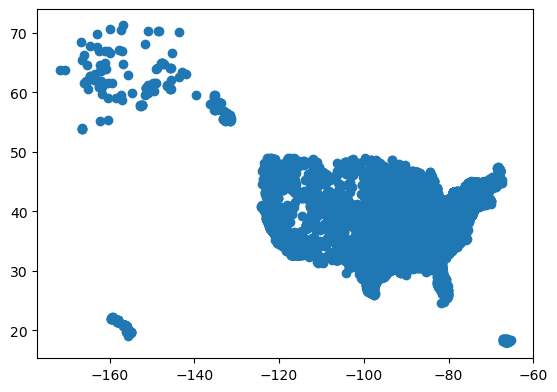

In [7]:
power_plants.plot()

# f-string

In [8]:
print('CRS', power_plants.crs)

CRS EPSG:4269


In [9]:
# Explore CRS
print(f"ellipsoid: {power_plants.crs.ellipsoid}")

ellipsoid: GRS 1980


In [10]:
# Any expression can go inside the curly brackets
print(f"The data has {len(power_plants):,} power plants")

print(f"Average installed capacity {power_plants['install_mw'].mean():.2f} MW")

The data has 13,445 power plants
Average installed capacity 99.39 MW


## Import US states shapefile

In [11]:
fp = os.path.join('data', 'tl_2026_us_state', 'tl_2026_us_state.shp')
states = gpd.read_file(fp)

states.head(3)

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


EPSG:4269


<Axes: >

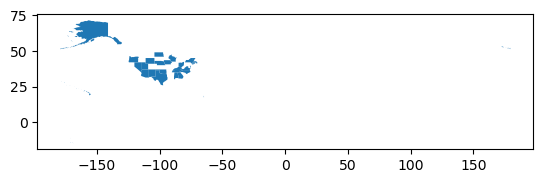

In [12]:
# Plot
print(states.crs)
states.plot()

# for loops

In [13]:
# Simplify column names

states.columns = states.columns.str.lower()
states.columns

Index(['region', 'division', 'statefp', 'statens', 'geoid', 'geoidfq',
       'stusps', 'name', 'lsad', 'mtfcc', 'funcstat', 'aland', 'awater',
       'intptlat', 'intptlon', 'geometry'],
      dtype='object')

In [14]:
# Check data type of codes columns
print(f"region is string dtype? {is_string_dtype(states['region'])}")
print(f"statefp is string dtype? {is_string_dtype(states['statefp'])}")
print(f"division is string dtype? {is_string_dtype(states['division'])}")

region is string dtype? True
statefp is string dtype? True
division is string dtype? True


In [15]:
# Another way of calling the function
pd.api.types.is_string_dtype(states['region'])

True

In [16]:
code_cols = ['region','division', 'statefp']

# Check whether columns are strings
for column in code_cols:
    print(f"{column} is string dtype? {is_string_dtype(states[column])}")

region is string dtype? True
division is string dtype? True
statefp is string dtype? True


## `assert`

We want to update the data type of columns from strings to integers. And we want to check it worked without printing things.

In [22]:
# Update code columns into integers
for column in code_cols:
    states[column] = states[column].astype('int')
    assert is_numeric_dtype(states[column])

 How does `assert` work?

In [23]:
2+2 == 4

True

In [24]:
# Does nothing if statement is True
assert 2+2 == 4

In [25]:
2+2 == 3

False

In [26]:
# Raises an error if statement is False
assert 2+2 == 3

AssertionError: 